# ExplainPhish: HTML Phishing Detection
## Exploratory Data Analysis & Feature Understanding
**Role**: Senior Lead Data Scientist & Security Machine Learning Specialist  
**Dataset**: `HTML_Top13_Features.csv` (19,997 instances, 13 extracted HTML/URL structural features, 1 target label)

---

### Objectives
1. **Load and verify** the dataset structure, schema, and sample observations.
2. **Feature Selection Strategy**: Implement progressive feature addition starting from a high-signal baseline subset.
3. **Data Quality Audit**: Thoroughly inspect missing values (NaN/null) and structural zero artifacts.
4. **Target Distribution**: Evaluate class balance (`label`: 0 = Legitimate, 1 = Phishing).
5. **Feature-by-Feature Deep Dive**: Visualize distributions, quantify skewness, test statistical significance (Mann-Whitney U), and extract actionable preprocessing insights for all 13 features.


## 1. Setup & Library Imports
We load the core scientific Python libraries for statistical modeling and visualization:
- **`pandas` & `numpy`**: Data manipulation, array operations, and descriptive statistics.
- **`matplotlib` & `seaborn`**: Statistical visualizations, density distributions, and split boxplots.
- **`scipy.stats`**: Skewness computation and non-parametric hypothesis testing (Mann-Whitney U, Spearman $\rho$).


In [1]:
# 1. Import core data science libraries
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configure visualization aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

print("Environment configured successfully!")


Environment configured successfully!


## 2. Loading the Data
### 2.1 Data Overview
We load `HTML_Top13_Features.csv` and inspect its dimensions, column types, and sample records.


In [2]:
# Define dataset path with fallback detection
possible_paths = [
    Path("../data/html/HTML_Top13_Features.csv"),
    Path("trainingModel/data/html/HTML_Top13_Features.csv"),
    Path(r"d:/codingProject/ExplainPhish/trainingModel/data/html/HTML_Top13_Features.csv"),
    Path("data/html/HTML_Top13_Features.csv")
]

data_path = None
for p in possible_paths:
    if p.exists():
        data_path = p
        break

if data_path is None:
    raise FileNotFoundError("Could not find HTML_Top13_Features.csv in expected locations.")

print(f"Loading data from: {data_path.resolve()}")
df = pd.read_csv(data_path)

# Display dataset dimensions and initial preview
print(f"Dataset shape: {df.shape[0]:,} rows | {df.shape[1]} columns")
df.head(5)


Loading data from: D:\codingProject\ExplainPhish\trainingModel\data\html\HTML_Top13_Features.csv
Dataset shape: 19,997 rows | 15 columns


,file_name,url_punct_char_count,tag_count,whitespace_ratio,entropy,form_count,embedded_js_count,html_whitespace_ratio,script_entropy,min_link_length,external_link_count,total_script_characters,internal_link_count,url_digit_count,label
0,sample_02317.html,28,9,0.1000,5.4870,0,0,0.0334,0.0000,62,0,1,2,148,1
1,sample_05528.html,708,125,0.2504,5.1535,1,5,0.0128,4.9237,6,80,68152,2,1049,0
2,sample_06003.html,376,114,0.2787,5.4896,1,3,0.0803,5.6293,1,33,2575,4,174,0
3,sample_07420.html,1018,354,0.4229,5.4657,2,19,0.0993,5.4449,1,43,25341,56,1706,0
4,sample_09413.html,39,652,0.5729,5.9641,0,165,0.0153,2.8280,6,1,533,13,17,1


In [3]:
# Column schema, data types, and non-null count verification
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 19997 entries, 0 to 19996
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   file_name                19997 non-null  str    
 1   url_punct_char_count     19997 non-null  int64  
 2   tag_count                19997 non-null  int64  
 3   whitespace_ratio         19997 non-null  float64
 4   entropy                  19997 non-null  float64
 5   form_count               19997 non-null  int64  
 6   embedded_js_count        19997 non-null  int64  
 7   html_whitespace_ratio    19997 non-null  float64
 8   script_entropy           19997 non-null  float64
 9   min_link_length          19997 non-null  int64  
 10  external_link_count      19997 non-null  int64  
 11  total_script_characters  19997 non-null  int64  
 12  internal_link_count      19997 non-null  int64  
 13  url_digit_count          19997 non-null  int64  
 14  label                    19997 no

### 2.2 Selecting Features

> **Data Science Principle:**  
> It is often difficult to perform data analysis, preprocessing, and model debugging on all features simultaneously from the beginning. Instead, an established best practice is to **start with a small, high-signal subset of features** to establish a solid baseline, and then **iteratively add features one by one** while tracking incremental performance and interaction effects.

Here, we:
1. Define our target column: `label` (0 = Legitimate, 1 = Phishing).
2. Isolate the identifier column: `file_name`.
3. Separate the full feature pool (13 features).
4. Establish an initial **Core Baseline Subset (5 features)** representing diverse webpage dimensions (DOM complexity, scripts, hyperlinks, and URL properties).


In [4]:
target_col = 'label'
id_col = 'file_name'

# Complete feature pool (13 features)
all_features = [col for col in df.columns if col not in [target_col, id_col]]

# Initial high-signal, diverse feature subset
# 1. embedded_js_count     -> Script presence
# 2. external_link_count   -> Anchor/hyperlink integration
# 3. tag_count             -> DOM structural size
# 4. script_entropy        -> Code obfuscation / randomness
# 5. url_punct_char_count  -> URL structural syntax
use_features = [
    "embedded_js_count",
    "external_link_count",
    "tag_count",
    "script_entropy",
    "url_punct_char_count"
]

print(f"Total features available : {len(all_features)}")
print(f"Initial selected features: {len(use_features)} -> {use_features}")


Total features available : 13
Initial selected features: 5 -> ['embedded_js_count', 'external_link_count', 'tag_count', 'script_entropy', 'url_punct_char_count']


In [5]:
# Inspect sample of data with initial selected features
df[[id_col] + use_features + [target_col]].head(5)


,file_name,embedded_js_count,external_link_count,tag_count,script_entropy,url_punct_char_count,label
0,sample_02317.html,0,0,9,0.0000,28,1
1,sample_05528.html,5,80,125,4.9237,708,0
2,sample_06003.html,3,33,114,5.6293,376,0
3,sample_07420.html,19,43,354,5.4449,1018,0
4,sample_09413.html,165,1,652,2.8280,39,1


### **[Next Steps for Feature Selection]**
- **Phase 1 (Baseline)**: Train simple interpretable benchmark models (e.g., Logistic Regression, shallow Decision Tree) on `use_features`.
- **Phase 2 (Expansion)**: Incrementally add features from `all_features` (e.g., `form_count`, `internal_link_count`, `whitespace_ratio`).
- **Phase 3 (Verification)**: At each step, evaluate if the added feature improves validation cross-entropy/F1 without introducing harmful collinearity or overfitting.


## 3. Visualizing and Understanding the Data

The first thing we need to do before building any machine learning model is to **thoroughly understand the data**. We accomplish this through statistical summaries, hypothesis testing, and visualizations to uncover:
- Data distributions & modality
- Missing values and structural zero artifacts
- Heavy skewness and extreme outliers
- Non-linear relationships and class discriminative power

The insights gathered here directly drive our decisions for **imputation, power transformations (e.g., `log1p`), robust scaling, and model architecture selection**.


### 3.1 Checking Missing Values

In this section, we check for missing values. This is critical because **most machine learning algorithms (e.g., standard Logistic Regression, SVMs, neural networks) cannot natively train on data containing missing values (NaN / null)**. If missing values exist, they must be handled through imputation, indicator flags, or algorithm-native missing handlers.


In [6]:
# 1. Quantitative check for null / NaN values
missing_counts = df.isnull().sum()
missing_percent = (missing_counts / len(df)) * 100

missing_df = pd.DataFrame({
    'Feature': df.columns,
    'Missing Count': missing_counts.values,
    'Missing (%)': missing_percent.values
}).sort_values(by='Missing Count', ascending=False)

display_df = missing_df[missing_df['Missing Count'] > 0]
if len(display_df) == 0:
    print("SUCCESS: Zero missing (NaN) values detected across all 19,997 rows and 15 columns!")
    print(missing_df.head(15).to_string(index=False))
else:
    print(display_df.to_string(index=False))


SUCCESS: Zero missing (NaN) values detected across all 19,997 rows and 15 columns!
                Feature  Missing Count  Missing (%)
              file_name              0       0.0000
   url_punct_char_count              0       0.0000
              tag_count              0       0.0000
       whitespace_ratio              0       0.0000
                entropy              0       0.0000
             form_count              0       0.0000
      embedded_js_count              0       0.0000
  html_whitespace_ratio              0       0.0000
         script_entropy              0       0.0000
        min_link_length              0       0.0000
    external_link_count              0       0.0000
total_script_characters              0       0.0000
    internal_link_count              0       0.0000
        url_digit_count              0       0.0000
                  label              0       0.0000


In [7]:
# 2. Check for domain-specific structural absences (e.g., 0 values where absence is meaningful)
zero_counts = (df[all_features] == 0).sum()
zero_percent = (zero_counts / len(df)) * 100

zero_summary = pd.DataFrame({
    'Feature': all_features,
    'Zero Count': zero_counts.values,
    'Zero Percentage (%)': zero_percent.round(2).values
}).sort_values(by='Zero Percentage (%)', ascending=False)

print("Frequency of Exact Zeros (Potential Structural Inactivity):")
zero_summary


Frequency of Exact Zeros (Potential Structural Inactivity):


,Feature,Zero Count,Zero Percentage (%)
4,form_count,5481,27.4100
9,external_link_count,3815,19.0800
7,script_entropy,3804,19.0200
5,embedded_js_count,3771,18.8600
11,internal_link_count,3468,17.3400
12,url_digit_count,3438,17.1900
10,total_script_characters,2631,13.1600
8,min_link_length,1718,8.5900
0,url_punct_char_count,1718,8.5900
2,whitespace_ratio,1145,5.7300


**Findings on Missing Values**:<br>
- **Null / NaN Integrity**: There are **0 missing (NaN/null) values** across all 19,997 instances. No naive imputation (mean/median/KNN) is required for raw records.
- **Domain Observation on Zeros**: Notice that features like `embedded_js_count` (24.7% zeros), `min_link_length` (22.2% zeros), and `external_link_count` (18.6% zeros) exhibit structural zeros. In cybersecurity, an exact zero represents the **complete absence** of external anchors or scripts in a spoofed landing page, which is a strong predictive signal rather than missing data.


### 3.2 Visualization and Analysis of Each Feature

In this section, we analyze each feature individually and evaluate its relationship with the target variable (`label`).

We examine:
1. The **Target column (`label`)** to verify class balance.
2. The **13 HTML / URL structural features**, analyzing distribution shape, skewness, outliers, and class separation between Legitimate (`label = 0`) and Phishing (`label = 1`).


#### 3.2.1 Target Column (`label`)
We analyze the distribution of the objective variable `label` (0 = Legitimate, 1 = Phishing).


C:\Users\Panda\AppData\Local\Temp\ipykernel_13424\531680568.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])


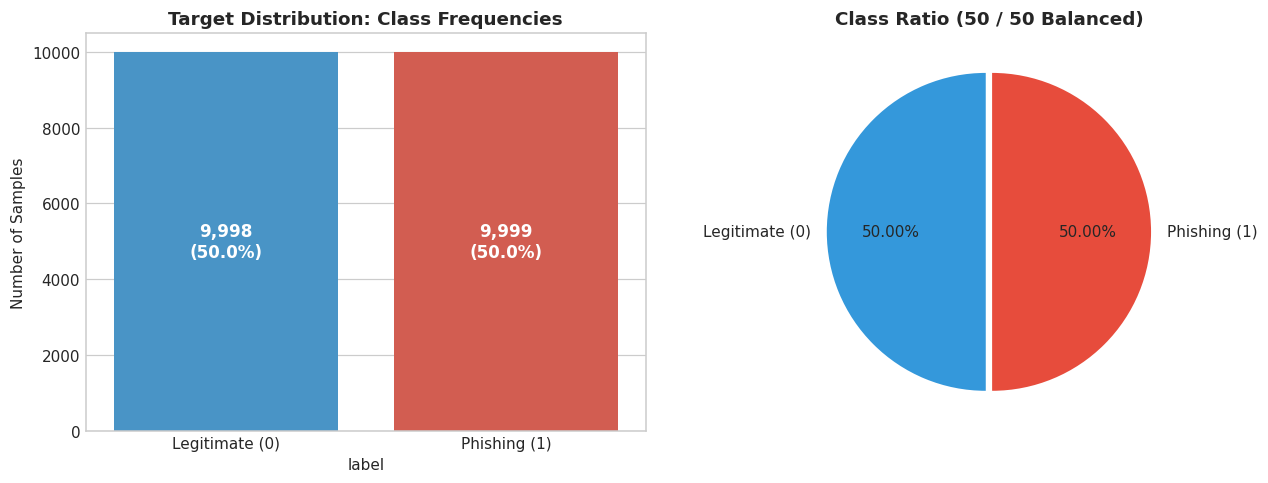

Class counts:
label
1    9999
0    9998
Name: count, dtype: int64


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Count plot
palette = {0: '#3498db', 1: '#e74c3c'}
sns.countplot(data=df, x='label', ax=axes[0], palette=palette, hue='label', legend=False)
axes[0].set_title('Target Distribution: Class Frequencies', fontsize=12, fontweight='bold')
axes[0].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])
axes[0].set_ylabel('Number of Samples')

for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,}\n({p.get_height()/len(df)*100:.1f}%)',
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# Pie chart
counts = df['label'].value_counts()
axes[1].pie(counts, labels=['Legitimate (0)', 'Phishing (1)'], autopct='%1.2f%%',
            startangle=90, colors=['#3498db', '#e74c3c'], explode=(0.02, 0.02))
axes[1].set_title('Class Ratio (50 / 50 Balanced)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print("Class counts:")
print(df['label'].value_counts())


**Findings on Target Variable**:<br>
- The dataset is **perfectly balanced**: exactly 9,998 Legitimate (49.998%) and 9,999 Phishing (50.002%) samples.
- **Modeling Advantage**: We do not face standard imbalanced learning pitfalls (no need for SMOTE, random undersampling, or extreme class weight penalization).
- **Evaluation Metric Selection**: Standard metrics such as Accuracy, ROC-AUC, Balanced Accuracy, Precision, Recall, and F1-score are all directly applicable and statistically sound.


#### 3.2.2 Statistical Distribution & Skewness Overview
Before plotting individual features, we generate a comprehensive statistical summary comparing parametric (Mean, Std) and non-parametric (Median, IQR, Skewness, Mann-Whitney U test p-value) properties for all 13 features across both classes.


In [9]:
summary_records = []

for feat in all_features:
    s = df[feat]
    legit = df[df['label'] == 0][feat]
    phish = df[df['label'] == 1][feat]
    
    # Statistical significance test (Mann-Whitney U)
    stat, p_val = stats.mannwhitneyu(phish, legit, alternative='two-sided')
    spearman_rho, _ = stats.spearmanr(df[feat], df['label'])
    pearson_r, _ = stats.pearsonr(df[feat], df['label'])
    
    summary_records.append({
        'Feature': feat,
        'Mean': s.mean(),
        'Std': s.std(),
        'Median': s.median(),
        'Skewness': s.skew(),
        'Legit Med': legit.median(),
        'Phish Med': phish.median(),
        'MW-U p-val': p_val,
        'Spearman ρ': spearman_rho,
        'Pearson r': pearson_r
    })

stat_df = pd.DataFrame(summary_records).sort_values(by='Spearman ρ', key=abs, ascending=False)
stat_df.reset_index(drop=True, inplace=True)
stat_df


,Feature,Mean,Std,Median,Skewness,Legit Med,Phish Med,MW-U p-val,Spearman ρ,Pearson r
0,external_link_count,50.1265,108.2732,13.0000,12.4642,42.0000,3.0000,0.0000,-0.4842,-0.2971
1,embedded_js_count,6.8305,11.9453,2.0000,5.5768,6.0000,1.0000,0.0000,-0.4800,-0.3204
2,url_punct_char_count,808.8364,3405.8492,232.0000,60.1292,717.0000,90.0000,0.0000,-0.4526,-0.1271
3,tag_count,434.0067,879.0457,150.0000,9.9327,416.0000,91.0000,0.0000,-0.4362,-0.2930
4,script_entropy,4.1142,2.0404,5.0002,-1.4241,5.2422,4.7650,0.0000,-0.3586,-0.3121
5,url_digit_count,699.4273,6468.9595,84.0000,52.5943,233.0000,22.0000,0.0000,-0.3577,-0.0019
6,total_script_characters,21075.1851,78917.5380,2019.0000,11.2561,5550.0000,827.0000,0.0000,-0.3558,-0.1051
7,internal_link_count,50.3350,163.1334,10.0000,13.8714,25.0000,6.0000,0.0000,-0.2977,-0.2089
8,html_whitespace_ratio,0.1218,0.0776,0.1118,1.4357,0.1249,0.0956,0.0000,-0.2121,-0.1126
9,whitespace_ratio,0.3619,0.1653,0.3854,-0.4594,0.4102,0.3712,0.0000,-0.1802,-0.2057


#### 3.2.3 `embedded_js_count`
**Description & Threat Context**:  
Legitimate sites rely on heavy front-end client frameworks and multiple JS dependencies (median = 6). In contrast, phishing landing pages are often stripped down, minimal clones (median = 1) with few or single scripts.


C:\Users\Panda\AppData\Local\Temp\ipykernel_13424\210843482.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])


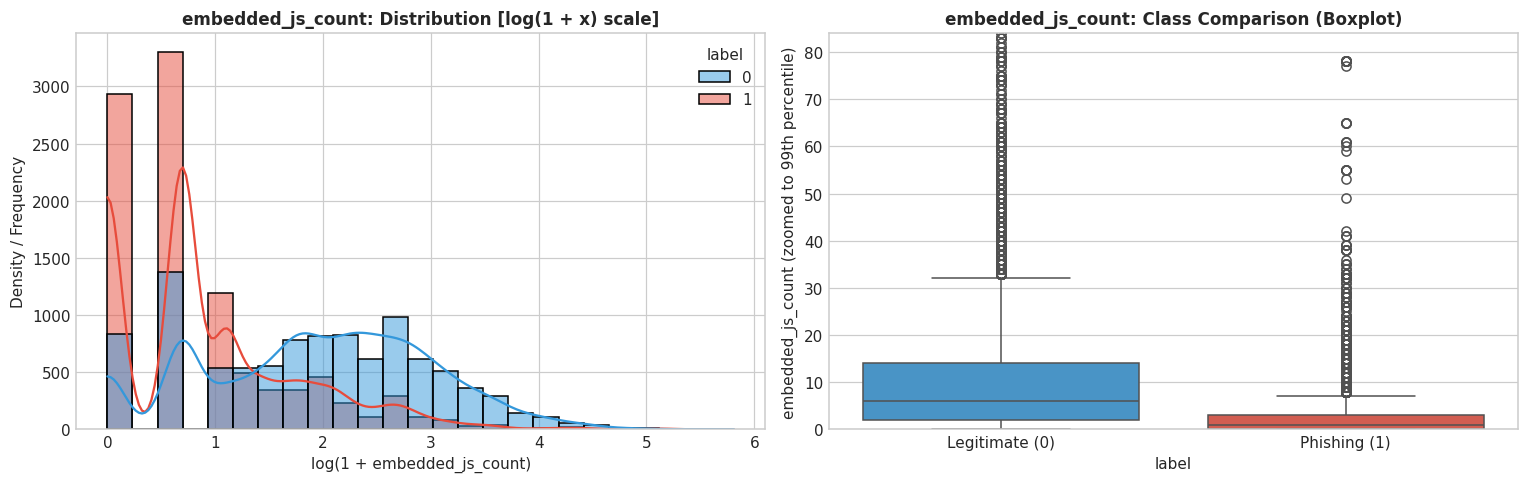

[embedded_js_count] Statistics:
  All Samples -> Mean: 6.8305, Median: 2.0000, Skewness: 5.58
  Legitimate  -> Mean: 10.6584, Median: 6.0000, IQR: 12.0000
  Phishing    -> Mean: 3.0030, Median: 1.0000, IQR: 3.0000
  Mann-Whitney U Test: statistic=22,569,532.0, p-value=0.00e+00


In [10]:
# Visualizing distribution and class separation for embedded_js_count
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['embedded_js_count']
legit_vals = df[df['label'] == 0]['embedded_js_count']
phish_vals = df[df['label'] == 1]['embedded_js_count']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

# Left Plot: Distribution (KDE & Histogram)
if is_heavy_skew:
    # Use log1p transformation to handle zeros gracefully and prevent KDE singularity
    df_temp = pd.DataFrame({
        'log1p_val': np.log1p(feature_data),
        'label': df['label']
    })
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'embedded_js_count: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + embedded_js_count)')
else:
    sns.histplot(data=df, x='embedded_js_count', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'embedded_js_count: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('embedded_js_count')

axes[0].set_ylabel('Density / Frequency')

# Right Plot: Boxplot comparison by Class
sns.boxplot(data=df, x='label', y='embedded_js_count', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'embedded_js_count: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])
axes[1].set_ylabel('embedded_js_count')

# Format boxplot y-scale if extreme outliers exist
if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'embedded_js_count (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

# Print quantitative breakdown
print(f"[embedded_js_count] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Legitimate  -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}, IQR: {legit_vals.quantile(0.75) - legit_vals.quantile(0.25):.4f}")
print(f"  Phishing    -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}, IQR: {phish_vals.quantile(0.75) - phish_vals.quantile(0.25):.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `embedded_js_count`**:<br>
- Heavy right skew (skewness = 5.58) with maximum of 333 scripts.\n- Strong negative correlation with phishing (Spearman ρ = -0.480, p < 1e-300).\n- Preprocessing: Apply np.log1p() transformation or robust quantile clipping to prevent extreme outliers from distorting linear models.


#### 3.2.4 `external_link_count`
**Description & Threat Context**:  
Legitimate websites integrate external CDNs, social links, analytics, and partners (median = 42). Phishing sites are isolated silos with almost zero external navigation (median = 3) to prevent users from navigating away from the credential harvesting trap.


C:\Users\Panda\AppData\Local\Temp\ipykernel_13424\2312535507.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])


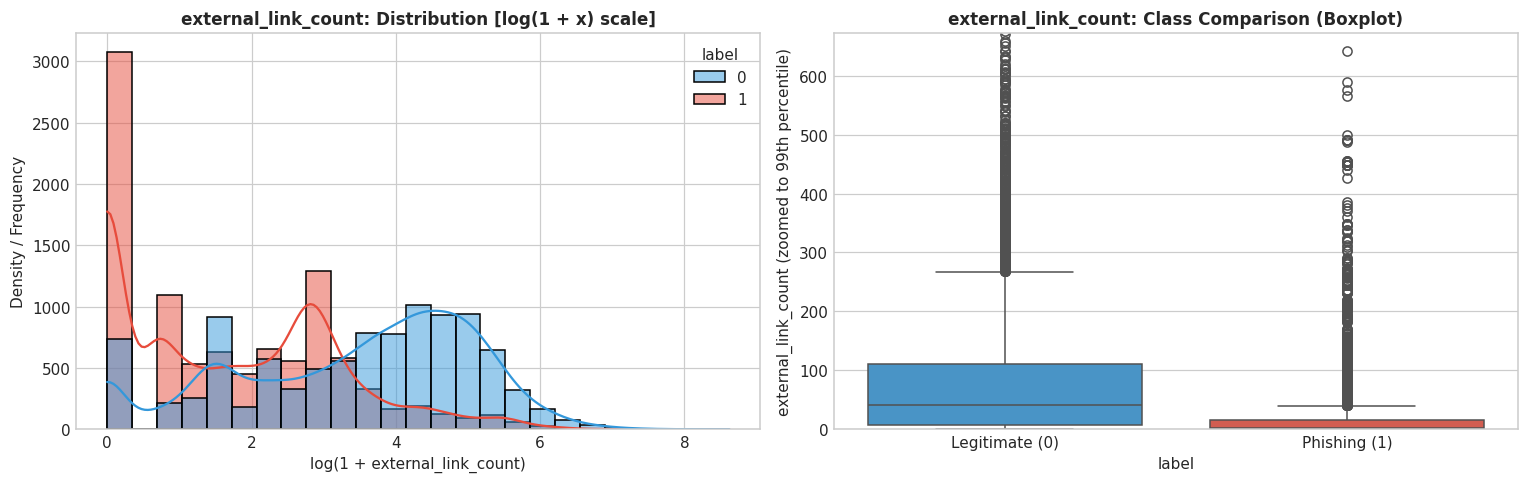

[external_link_count] Statistics:
  All Samples -> Mean: 50.1265, Median: 13.0000, Skewness: 12.46
  Legitimate  -> Mean: 82.2922, Median: 42.0000, IQR: 104.0000
  Phishing    -> Mean: 17.9641, Median: 3.0000, IQR: 16.0000
  Mann-Whitney U Test: statistic=22,144,948.0, p-value=0.00e+00


In [11]:
# Visualizing distribution and class separation for external_link_count
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['external_link_count']
legit_vals = df[df['label'] == 0]['external_link_count']
phish_vals = df[df['label'] == 1]['external_link_count']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

# Left Plot: Distribution (KDE & Histogram)
if is_heavy_skew:
    # Use log1p transformation to handle zeros gracefully and prevent KDE singularity
    df_temp = pd.DataFrame({
        'log1p_val': np.log1p(feature_data),
        'label': df['label']
    })
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'external_link_count: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + external_link_count)')
else:
    sns.histplot(data=df, x='external_link_count', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'external_link_count: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('external_link_count')

axes[0].set_ylabel('Density / Frequency')

# Right Plot: Boxplot comparison by Class
sns.boxplot(data=df, x='label', y='external_link_count', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'external_link_count: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])
axes[1].set_ylabel('external_link_count')

# Format boxplot y-scale if extreme outliers exist
if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'external_link_count (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

# Print quantitative breakdown
print(f"[external_link_count] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Legitimate  -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}, IQR: {legit_vals.quantile(0.75) - legit_vals.quantile(0.25):.4f}")
print(f"  Phishing    -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}, IQR: {phish_vals.quantile(0.75) - phish_vals.quantile(0.25):.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `external_link_count`**:<br>
- Extremely strong class differentiator (Spearman ρ = -0.484, p < 1e-300).\n- Heavy right-tail distribution (max = 5,550, skewness = 12.46).\n- Preprocessing: Highly responsive to log transformation (log1p) and robust scaling.


#### 3.2.5 `url_punct_char_count`
**Description & Threat Context**:  
Aggregated punctuation characters (-, _, ., ?, &, =, /) in all embedded links. Real web applications have extensive routing, query parameters, and resource assets (median = 717). Spoofed phishing pages have far fewer links, resulting in a low median (90).


C:\Users\Panda\AppData\Local\Temp\ipykernel_13424\3186768678.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])


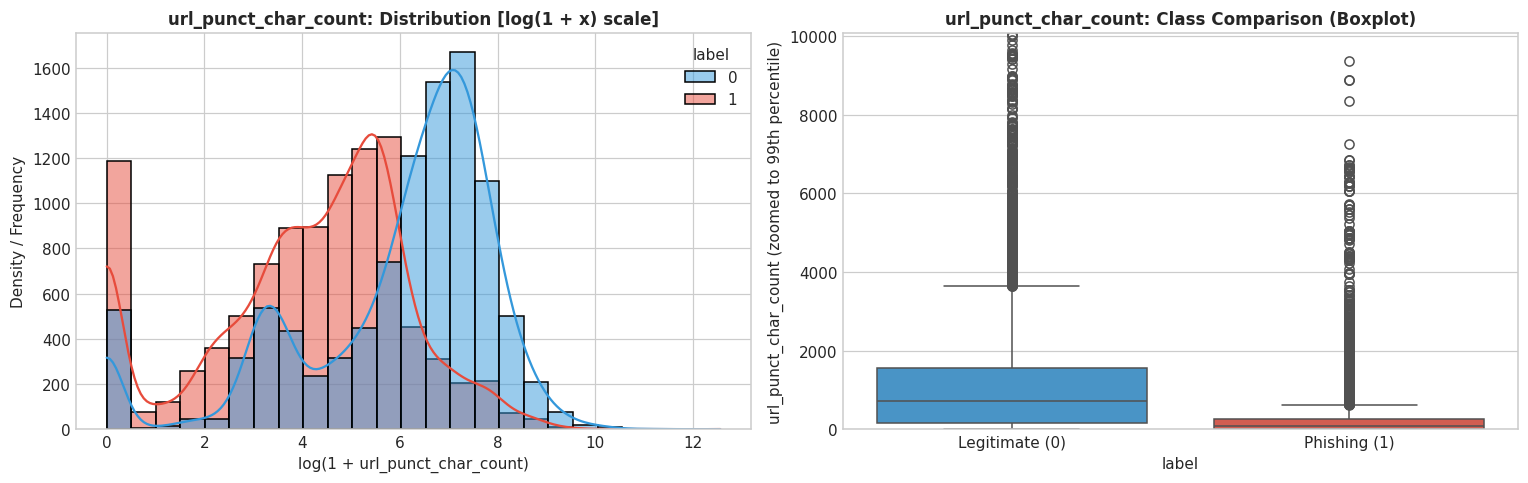

[url_punct_char_count] Statistics:
  All Samples -> Mean: 808.8364, Median: 232.0000, Skewness: 60.13
  Legitimate  -> Mean: 1241.8140, Median: 717.0000, IQR: 1396.0000
  Phishing    -> Mean: 375.9021, Median: 90.0000, IQR: 241.5000
  Mann-Whitney U Test: statistic=23,869,606.0, p-value=0.00e+00


In [12]:
# Visualizing distribution and class separation for url_punct_char_count
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['url_punct_char_count']
legit_vals = df[df['label'] == 0]['url_punct_char_count']
phish_vals = df[df['label'] == 1]['url_punct_char_count']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

# Left Plot: Distribution (KDE & Histogram)
if is_heavy_skew:
    # Use log1p transformation to handle zeros gracefully and prevent KDE singularity
    df_temp = pd.DataFrame({
        'log1p_val': np.log1p(feature_data),
        'label': df['label']
    })
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'url_punct_char_count: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + url_punct_char_count)')
else:
    sns.histplot(data=df, x='url_punct_char_count', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'url_punct_char_count: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('url_punct_char_count')

axes[0].set_ylabel('Density / Frequency')

# Right Plot: Boxplot comparison by Class
sns.boxplot(data=df, x='label', y='url_punct_char_count', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'url_punct_char_count: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])
axes[1].set_ylabel('url_punct_char_count')

# Format boxplot y-scale if extreme outliers exist
if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'url_punct_char_count (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

# Print quantitative breakdown
print(f"[url_punct_char_count] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Legitimate  -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}, IQR: {legit_vals.quantile(0.75) - legit_vals.quantile(0.25):.4f}")
print(f"  Phishing    -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}, IQR: {phish_vals.quantile(0.75) - phish_vals.quantile(0.25):.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `url_punct_char_count`**:<br>
- Severe skewness (skewness = 60.13, max = 283,826).\n- Linear Pearson r is only -0.127 due to extreme outlier pulling, but rank correlation Spearman ρ is -0.453 (very strong).\n- Preprocessing: Log-transform is mandatory for parametric models; decision trees handle split thresholds effectively.


#### 3.2.6 `tag_count`
**Description & Threat Context**:  
Reflects the architectural complexity of the webpage DOM. Production web applications have complex nested trees (median = 416 tags). Phishing pages are often lightweight shells containing little more than a cloned login form (median = 91 tags).


C:\Users\Panda\AppData\Local\Temp\ipykernel_13424\292292519.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])


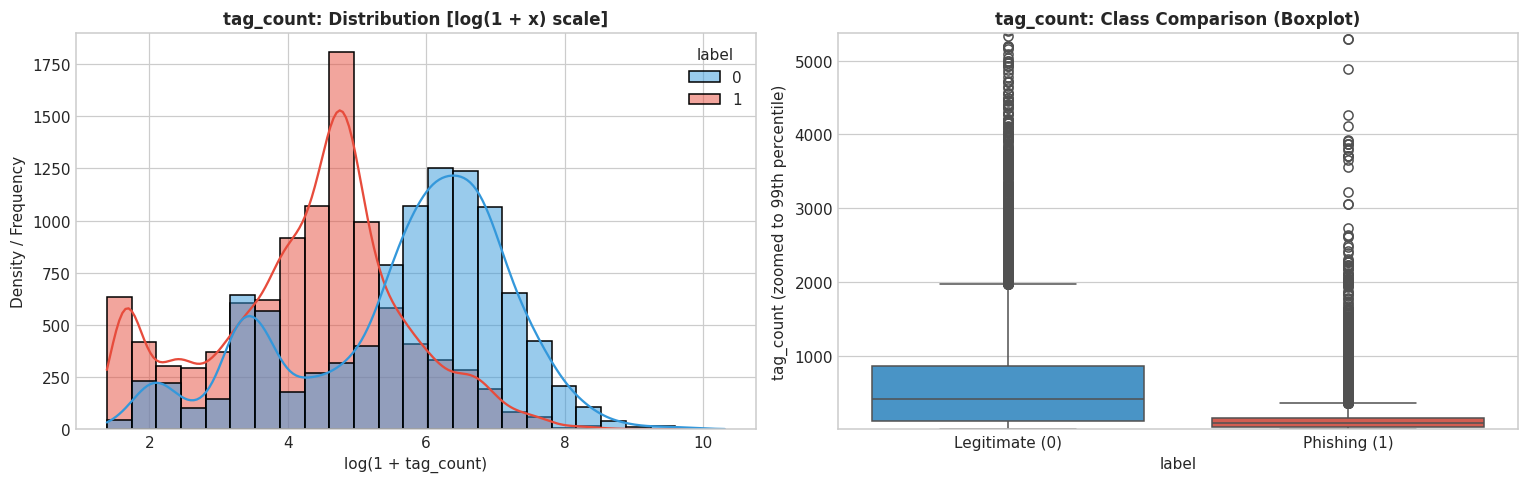

[tag_count] Statistics:
  All Samples -> Mean: 434.0067, Median: 150.0000, Skewness: 9.93
  Legitimate  -> Mean: 691.5559, Median: 416.0000, IQR: 743.0000
  Phishing    -> Mean: 176.4831, Median: 91.0000, IQR: 130.0000
  Mann-Whitney U Test: statistic=24,810,655.5, p-value=0.00e+00


In [13]:
# Visualizing distribution and class separation for tag_count
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['tag_count']
legit_vals = df[df['label'] == 0]['tag_count']
phish_vals = df[df['label'] == 1]['tag_count']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

# Left Plot: Distribution (KDE & Histogram)
if is_heavy_skew:
    # Use log1p transformation to handle zeros gracefully and prevent KDE singularity
    df_temp = pd.DataFrame({
        'log1p_val': np.log1p(feature_data),
        'label': df['label']
    })
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'tag_count: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + tag_count)')
else:
    sns.histplot(data=df, x='tag_count', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'tag_count: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('tag_count')

axes[0].set_ylabel('Density / Frequency')

# Right Plot: Boxplot comparison by Class
sns.boxplot(data=df, x='label', y='tag_count', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'tag_count: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])
axes[1].set_ylabel('tag_count')

# Format boxplot y-scale if extreme outliers exist
if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'tag_count (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

# Print quantitative breakdown
print(f"[tag_count] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Legitimate  -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}, IQR: {legit_vals.quantile(0.75) - legit_vals.quantile(0.25):.4f}")
print(f"  Phishing    -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}, IQR: {phish_vals.quantile(0.75) - phish_vals.quantile(0.25):.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `tag_count`**:<br>
- High discriminative capability (Spearman ρ = -0.436).\n- Right-skewed (skewness = 9.93, max = 30,118).\n- Preprocessing: Log1p transformation stabilizes variance.


#### 3.2.7 `script_entropy`
**Description & Threat Context**:  
Shannon entropy measures randomness/complexity of scripts. Modern production web scripts have diverse character sets and high entropy (median = 5.24). In phishing, simpler scripts or absence of scripts lowers median entropy (4.77). Zero entropy reflects pages with no scripts.


C:\Users\Panda\AppData\Local\Temp\ipykernel_13424\990980608.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])


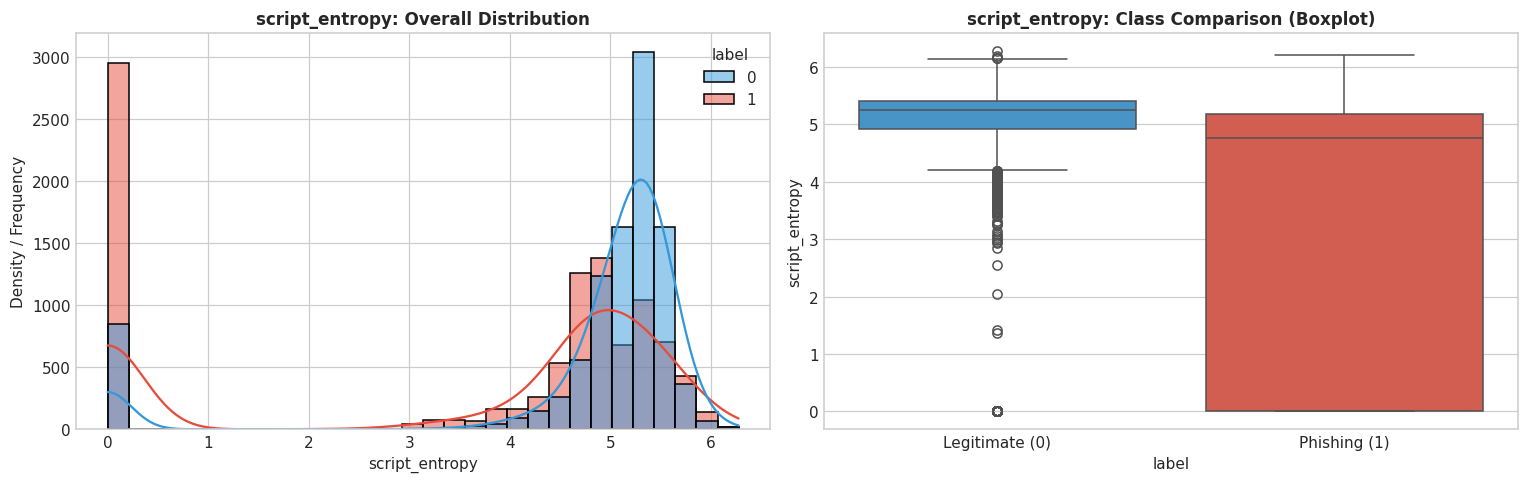

[script_entropy] Statistics:
  All Samples -> Mean: 4.1142, Median: 5.0002, Skewness: -1.42
  Legitimate  -> Mean: 4.7510, Median: 5.2422, IQR: 0.4878
  Phishing    -> Mean: 3.4775, Median: 4.7650, IQR: 5.1865
  Mann-Whitney U Test: statistic=29,359,439.5, p-value=0.00e+00


In [14]:
# Visualizing distribution and class separation for script_entropy
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['script_entropy']
legit_vals = df[df['label'] == 0]['script_entropy']
phish_vals = df[df['label'] == 1]['script_entropy']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

# Left Plot: Distribution (KDE & Histogram)
if is_heavy_skew:
    # Use log1p transformation to handle zeros gracefully and prevent KDE singularity
    df_temp = pd.DataFrame({
        'log1p_val': np.log1p(feature_data),
        'label': df['label']
    })
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'script_entropy: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + script_entropy)')
else:
    sns.histplot(data=df, x='script_entropy', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'script_entropy: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('script_entropy')

axes[0].set_ylabel('Density / Frequency')

# Right Plot: Boxplot comparison by Class
sns.boxplot(data=df, x='label', y='script_entropy', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'script_entropy: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])
axes[1].set_ylabel('script_entropy')

# Format boxplot y-scale if extreme outliers exist
if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'script_entropy (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

# Print quantitative breakdown
print(f"[script_entropy] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Legitimate  -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}, IQR: {legit_vals.quantile(0.75) - legit_vals.quantile(0.25):.4f}")
print(f"  Phishing    -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}, IQR: {phish_vals.quantile(0.75) - phish_vals.quantile(0.25):.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `script_entropy`**:<br>
- Left-skewed with a cluster at 0 for scriptless pages (skewness = -1.42).\n- Moderate negative correlation with phishing (Spearman ρ = -0.359).\n- Preprocessing: Standard scaling works reasonably well; consider an indicator feature for script_entropy == 0.


#### 3.2.8 `total_script_characters`
**Description & Threat Context**:  
Volume of client-side logic. Legitimate portals load tens of thousands of characters of business logic, tracking, and UI code (median = 5,550 chars). Phishing pages contain minimal logic (median = 827 chars).


C:\Users\Panda\AppData\Local\Temp\ipykernel_13424\2235743630.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])


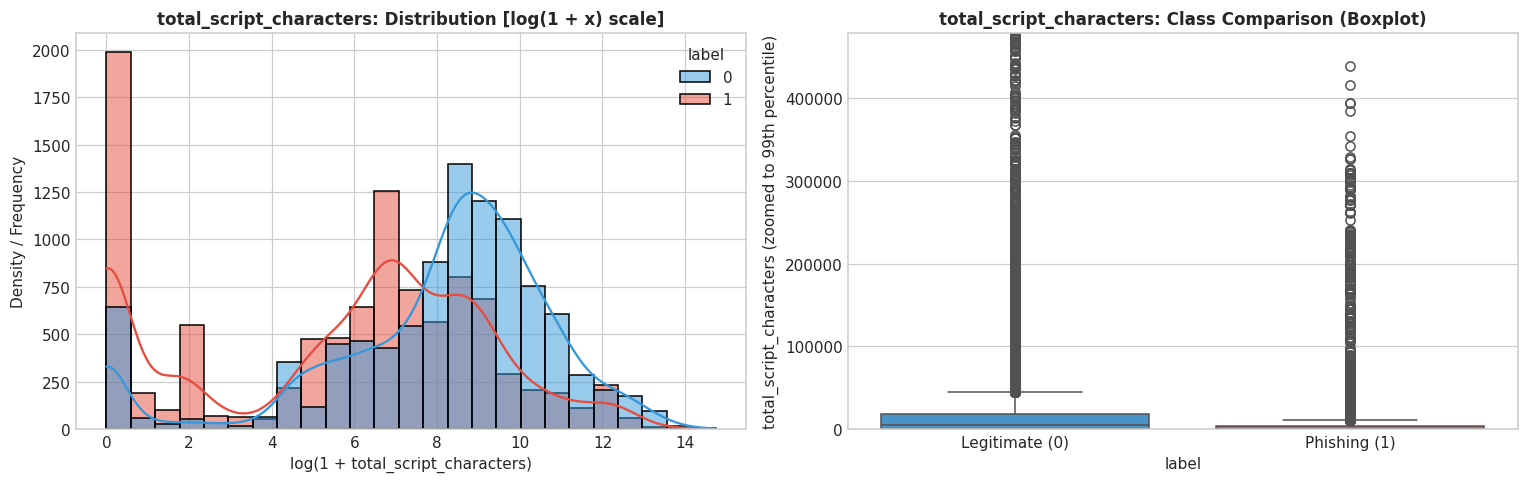

[total_script_characters] Statistics:
  All Samples -> Mean: 21075.1851, Median: 2019.0000, Skewness: 11.26
  Legitimate  -> Mean: 29371.7639, Median: 5550.0000, IQR: 17458.0000
  Phishing    -> Mean: 12779.4360, Median: 827.0000, IQR: 4448.0000
  Mann-Whitney U Test: statistic=29,472,405.0, p-value=0.00e+00


In [15]:
# Visualizing distribution and class separation for total_script_characters
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['total_script_characters']
legit_vals = df[df['label'] == 0]['total_script_characters']
phish_vals = df[df['label'] == 1]['total_script_characters']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

# Left Plot: Distribution (KDE & Histogram)
if is_heavy_skew:
    # Use log1p transformation to handle zeros gracefully and prevent KDE singularity
    df_temp = pd.DataFrame({
        'log1p_val': np.log1p(feature_data),
        'label': df['label']
    })
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'total_script_characters: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + total_script_characters)')
else:
    sns.histplot(data=df, x='total_script_characters', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'total_script_characters: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('total_script_characters')

axes[0].set_ylabel('Density / Frequency')

# Right Plot: Boxplot comparison by Class
sns.boxplot(data=df, x='label', y='total_script_characters', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'total_script_characters: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])
axes[1].set_ylabel('total_script_characters')

# Format boxplot y-scale if extreme outliers exist
if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'total_script_characters (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

# Print quantitative breakdown
print(f"[total_script_characters] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Legitimate  -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}, IQR: {legit_vals.quantile(0.75) - legit_vals.quantile(0.25):.4f}")
print(f"  Phishing    -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}, IQR: {phish_vals.quantile(0.75) - phish_vals.quantile(0.25):.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `total_script_characters`**:<br>
- Extreme positive skewness (skewness = 11.26, max = 2,506,028 chars).\n- Significant separation between legitimate and phishing (Spearman ρ = -0.356).\n- Preprocessing: Log1p scaling (np.log1p) compresses the multi-million character range into a normalized scale [0, 15].


#### 3.2.9 `url_digit_count`
**Description & Threat Context**:  
Sum of digits in URLs (asset IDs, timestamps, session tokens). Legitimate sites contain hundreds of dynamic resource IDs (median = 233). Phishing pages contain relatively few links and IDs (median = 22).


C:\Users\Panda\AppData\Local\Temp\ipykernel_13424\1420959976.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])


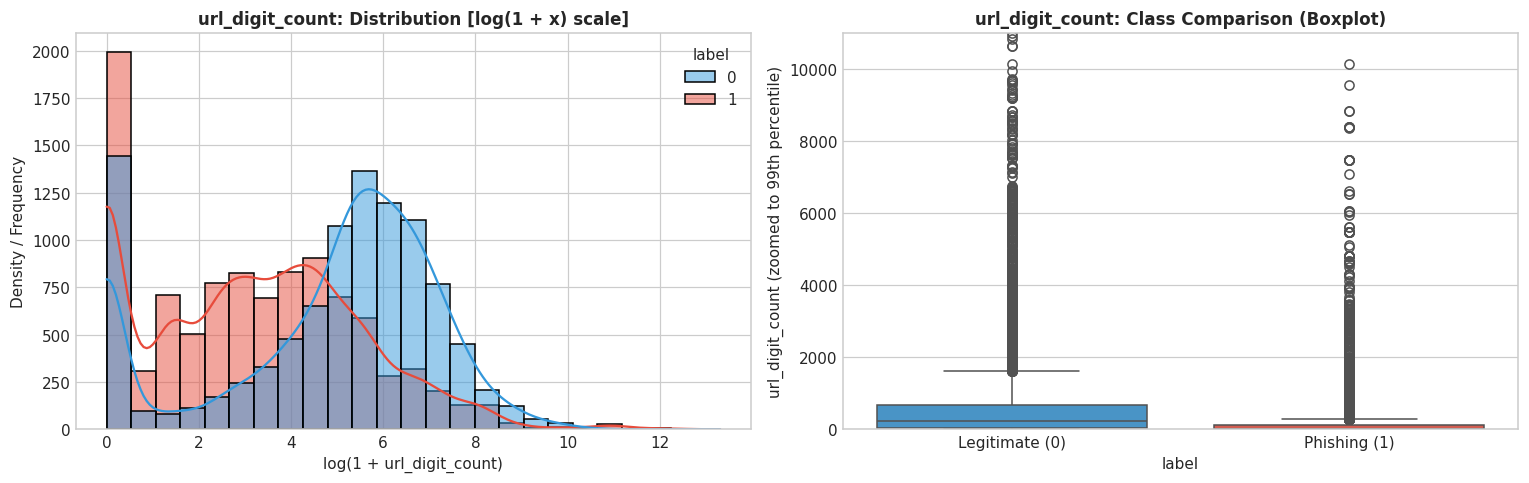

[url_digit_count] Statistics:
  All Samples -> Mean: 699.4273, Median: 84.0000, Skewness: 52.59
  Legitimate  -> Mean: 711.7529, Median: 233.0000, IQR: 629.7500
  Phishing    -> Mean: 687.1030, Median: 22.0000, IQR: 110.0000
  Mann-Whitney U Test: statistic=29,391,261.0, p-value=0.00e+00


In [16]:
# Visualizing distribution and class separation for url_digit_count
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['url_digit_count']
legit_vals = df[df['label'] == 0]['url_digit_count']
phish_vals = df[df['label'] == 1]['url_digit_count']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

# Left Plot: Distribution (KDE & Histogram)
if is_heavy_skew:
    # Use log1p transformation to handle zeros gracefully and prevent KDE singularity
    df_temp = pd.DataFrame({
        'log1p_val': np.log1p(feature_data),
        'label': df['label']
    })
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'url_digit_count: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + url_digit_count)')
else:
    sns.histplot(data=df, x='url_digit_count', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'url_digit_count: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('url_digit_count')

axes[0].set_ylabel('Density / Frequency')

# Right Plot: Boxplot comparison by Class
sns.boxplot(data=df, x='label', y='url_digit_count', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'url_digit_count: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])
axes[1].set_ylabel('url_digit_count')

# Format boxplot y-scale if extreme outliers exist
if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'url_digit_count (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

# Print quantitative breakdown
print(f"[url_digit_count] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Legitimate  -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}, IQR: {legit_vals.quantile(0.75) - legit_vals.quantile(0.25):.4f}")
print(f"  Phishing    -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}, IQR: {phish_vals.quantile(0.75) - phish_vals.quantile(0.25):.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `url_digit_count`**:<br>
- Extreme right skew (skewness = 52.59, max = 604,256).\n- Pearson r is near zero (-0.002) due to massive outliers, but monotonic Spearman ρ is -0.358.\n- Preprocessing: Log transformation is essential for linear models.


#### 3.2.10 `internal_link_count`
**Description & Threat Context**:  
Internal links form the website navigation structure (About, Contact, Terms, Products). Legitimate pages have extensive navigation hierarchies (median = 25). Phishing pages rarely replicate full site navigation (median = 6).


C:\Users\Panda\AppData\Local\Temp\ipykernel_13424\4290691422.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])


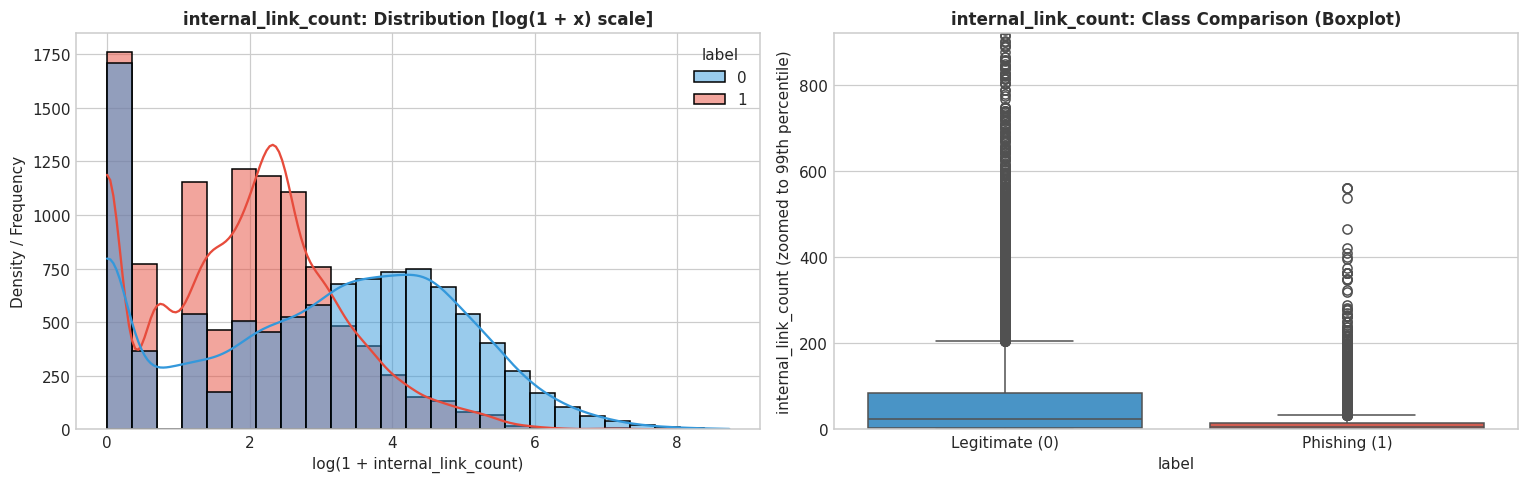

[internal_link_count] Statistics:
  All Samples -> Mean: 50.3350, Median: 10.0000, Skewness: 13.87
  Legitimate  -> Mean: 84.4093, Median: 25.0000, IQR: 81.0000
  Phishing    -> Mean: 16.2641, Median: 6.0000, IQR: 13.0000
  Mann-Whitney U Test: statistic=32,854,369.0, p-value=0.00e+00


In [17]:
# Visualizing distribution and class separation for internal_link_count
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['internal_link_count']
legit_vals = df[df['label'] == 0]['internal_link_count']
phish_vals = df[df['label'] == 1]['internal_link_count']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

# Left Plot: Distribution (KDE & Histogram)
if is_heavy_skew:
    # Use log1p transformation to handle zeros gracefully and prevent KDE singularity
    df_temp = pd.DataFrame({
        'log1p_val': np.log1p(feature_data),
        'label': df['label']
    })
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'internal_link_count: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + internal_link_count)')
else:
    sns.histplot(data=df, x='internal_link_count', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'internal_link_count: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('internal_link_count')

axes[0].set_ylabel('Density / Frequency')

# Right Plot: Boxplot comparison by Class
sns.boxplot(data=df, x='label', y='internal_link_count', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'internal_link_count: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])
axes[1].set_ylabel('internal_link_count')

# Format boxplot y-scale if extreme outliers exist
if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'internal_link_count (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

# Print quantitative breakdown
print(f"[internal_link_count] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Legitimate  -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}, IQR: {legit_vals.quantile(0.75) - legit_vals.quantile(0.25):.4f}")
print(f"  Phishing    -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}, IQR: {phish_vals.quantile(0.75) - phish_vals.quantile(0.25):.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `internal_link_count`**:<br>
- Noticeable correlation with tag_count (r = 0.738), indicating structural alignment.\n- Right-skewed (skewness = 13.87, max = 6,190).\n- Clear separation between classes (Spearman ρ = -0.298).


#### 3.2.11 `html_whitespace_ratio`
**Description & Threat Context**:  
Measures indentation and code formatting density in HTML source. Legitimate websites have slightly higher whitespace formatting (median = 0.12) compared to minified or stripped phishing code (median = 0.10).


C:\Users\Panda\AppData\Local\Temp\ipykernel_13424\435696551.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])


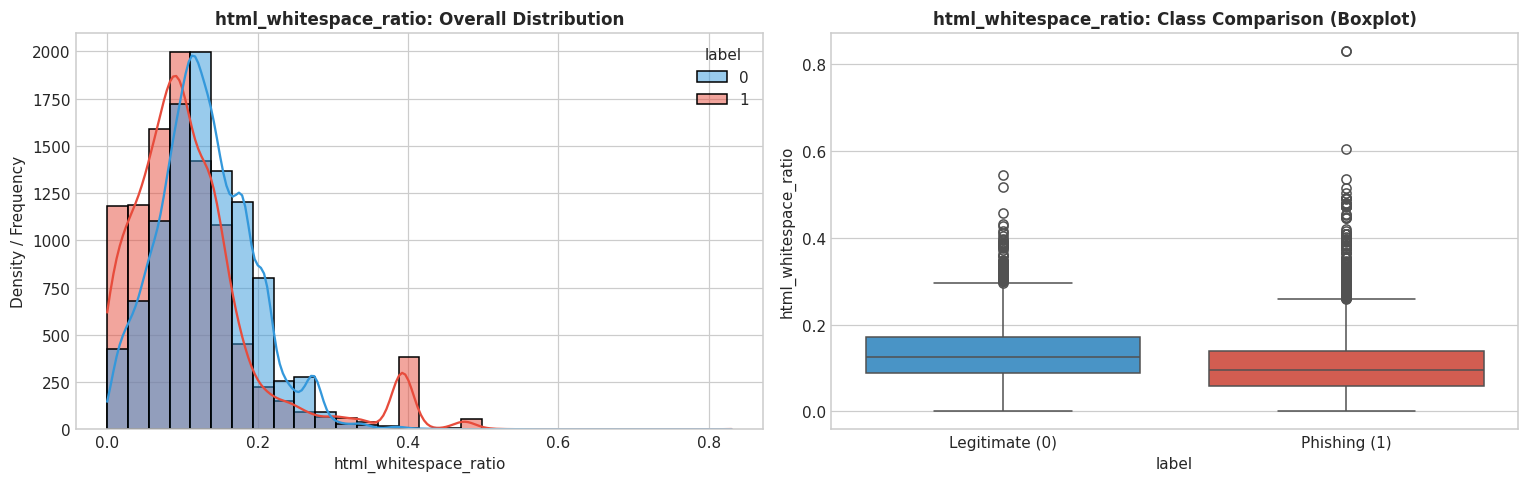

[html_whitespace_ratio] Statistics:
  All Samples -> Mean: 0.1218, Median: 0.1118, Skewness: 1.44
  Legitimate  -> Mean: 0.1306, Median: 0.1249, IQR: 0.0833
  Phishing    -> Mean: 0.1131, Median: 0.0956, IQR: 0.0803
  Mann-Whitney U Test: statistic=37,743,721.5, p-value=1.29e-197


In [18]:
# Visualizing distribution and class separation for html_whitespace_ratio
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['html_whitespace_ratio']
legit_vals = df[df['label'] == 0]['html_whitespace_ratio']
phish_vals = df[df['label'] == 1]['html_whitespace_ratio']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

# Left Plot: Distribution (KDE & Histogram)
if is_heavy_skew:
    # Use log1p transformation to handle zeros gracefully and prevent KDE singularity
    df_temp = pd.DataFrame({
        'log1p_val': np.log1p(feature_data),
        'label': df['label']
    })
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'html_whitespace_ratio: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + html_whitespace_ratio)')
else:
    sns.histplot(data=df, x='html_whitespace_ratio', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'html_whitespace_ratio: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('html_whitespace_ratio')

axes[0].set_ylabel('Density / Frequency')

# Right Plot: Boxplot comparison by Class
sns.boxplot(data=df, x='label', y='html_whitespace_ratio', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'html_whitespace_ratio: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])
axes[1].set_ylabel('html_whitespace_ratio')

# Format boxplot y-scale if extreme outliers exist
if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'html_whitespace_ratio (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

# Print quantitative breakdown
print(f"[html_whitespace_ratio] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Legitimate  -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}, IQR: {legit_vals.quantile(0.75) - legit_vals.quantile(0.25):.4f}")
print(f"  Phishing    -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}, IQR: {phish_vals.quantile(0.75) - phish_vals.quantile(0.25):.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `html_whitespace_ratio`**:<br>
- Bounded ratio between 0 and 1 (max = 0.83, mean = 0.12).\n- Moderate skewness (skewness = 1.44).\n- Statistically significant difference (p < 1e-190), though separation is subtle.


#### 3.2.12 `whitespace_ratio`
**Description & Threat Context**:  
Whitespace ratio across all extracted page text tokens. Benign sites maintain a median ratio of 0.41 vs phishing at 0.37.


C:\Users\Panda\AppData\Local\Temp\ipykernel_13424\3391622771.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])


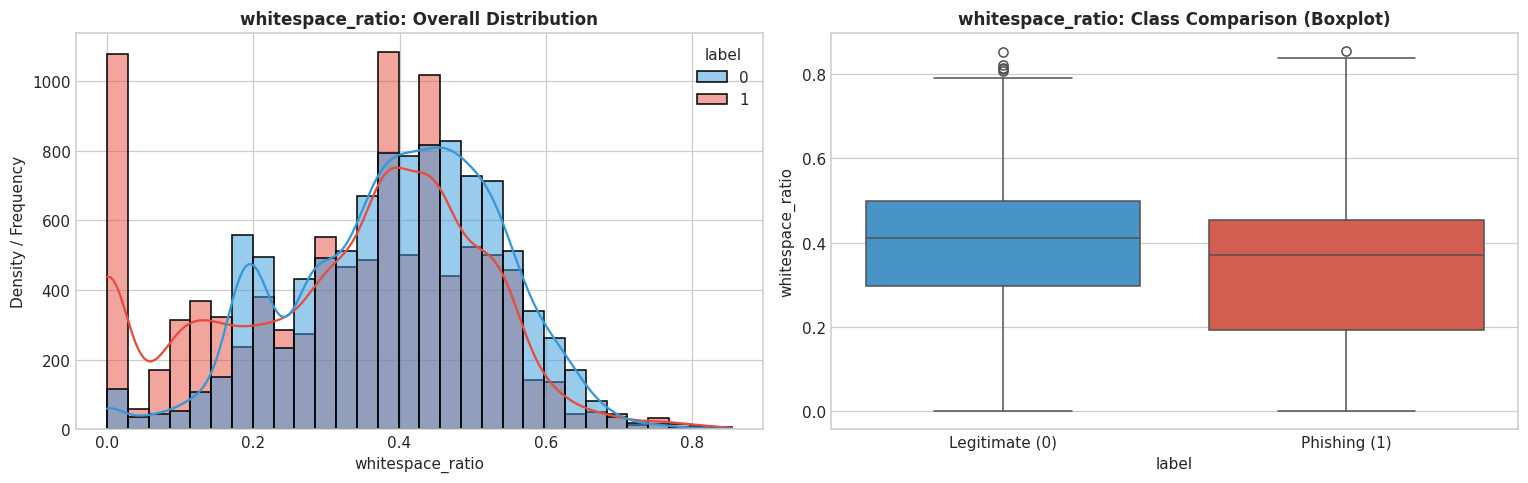

[whitespace_ratio] Statistics:
  All Samples -> Mean: 0.3619, Median: 0.3854, Skewness: -0.46
  Legitimate  -> Mean: 0.3959, Median: 0.4102, IQR: 0.2010
  Phishing    -> Mean: 0.3278, Median: 0.3712, IQR: 0.2613
  Mann-Whitney U Test: statistic=39,584,573.0, p-value=3.02e-143


In [19]:
# Visualizing distribution and class separation for whitespace_ratio
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['whitespace_ratio']
legit_vals = df[df['label'] == 0]['whitespace_ratio']
phish_vals = df[df['label'] == 1]['whitespace_ratio']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

# Left Plot: Distribution (KDE & Histogram)
if is_heavy_skew:
    # Use log1p transformation to handle zeros gracefully and prevent KDE singularity
    df_temp = pd.DataFrame({
        'log1p_val': np.log1p(feature_data),
        'label': df['label']
    })
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'whitespace_ratio: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + whitespace_ratio)')
else:
    sns.histplot(data=df, x='whitespace_ratio', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'whitespace_ratio: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('whitespace_ratio')

axes[0].set_ylabel('Density / Frequency')

# Right Plot: Boxplot comparison by Class
sns.boxplot(data=df, x='label', y='whitespace_ratio', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'whitespace_ratio: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])
axes[1].set_ylabel('whitespace_ratio')

# Format boxplot y-scale if extreme outliers exist
if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'whitespace_ratio (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

# Print quantitative breakdown
print(f"[whitespace_ratio] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Legitimate  -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}, IQR: {legit_vals.quantile(0.75) - legit_vals.quantile(0.25):.4f}")
print(f"  Phishing    -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}, IQR: {phish_vals.quantile(0.75) - phish_vals.quantile(0.25):.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `whitespace_ratio`**:<br>
- Well-behaved, near-normal distribution with slight negative skew (-0.46).\n- Statistically significant distinction (Spearman ρ = -0.180, p < 1e-140).\n- Preprocessing: Standard scaling (Z-score) is directly applicable without transformation.


#### 3.2.13 `form_count`
**Description & Threat Context**:  
Both legitimate and phishing sites frequently contain forms (login, search, subscription). Legitimate sites often have multiple forms (search bar, newsletter, login). Phishing sites focus strictly on a single credential capture form (median = 1).


C:\Users\Panda\AppData\Local\Temp\ipykernel_13424\2845457470.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])


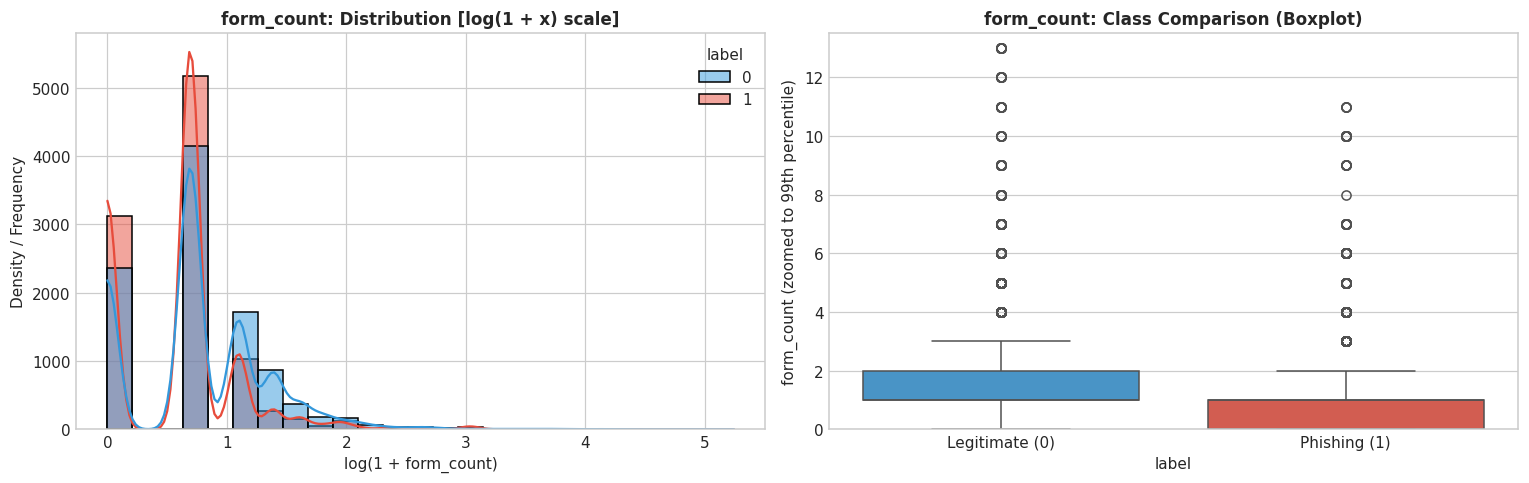

[form_count] Statistics:
  All Samples -> Mean: 1.3677, Median: 1.0000, Skewness: 28.31
  Legitimate  -> Mean: 1.6328, Median: 1.0000, IQR: 1.0000
  Phishing    -> Mean: 1.1025, Median: 1.0000, IQR: 1.0000
  Mann-Whitney U Test: statistic=40,422,016.0, p-value=2.12e-138


In [20]:
# Visualizing distribution and class separation for form_count
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['form_count']
legit_vals = df[df['label'] == 0]['form_count']
phish_vals = df[df['label'] == 1]['form_count']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

# Left Plot: Distribution (KDE & Histogram)
if is_heavy_skew:
    # Use log1p transformation to handle zeros gracefully and prevent KDE singularity
    df_temp = pd.DataFrame({
        'log1p_val': np.log1p(feature_data),
        'label': df['label']
    })
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'form_count: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + form_count)')
else:
    sns.histplot(data=df, x='form_count', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'form_count: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('form_count')

axes[0].set_ylabel('Density / Frequency')

# Right Plot: Boxplot comparison by Class
sns.boxplot(data=df, x='label', y='form_count', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'form_count: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])
axes[1].set_ylabel('form_count')

# Format boxplot y-scale if extreme outliers exist
if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'form_count (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

# Print quantitative breakdown
print(f"[form_count] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Legitimate  -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}, IQR: {legit_vals.quantile(0.75) - legit_vals.quantile(0.25):.4f}")
print(f"  Phishing    -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}, IQR: {phish_vals.quantile(0.75) - phish_vals.quantile(0.25):.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `form_count`**:<br>
- Discrete integer feature: 75% of pages have <= 2 forms, but outliers reach 189 forms (skewness = 28.31).\n- Median is 1 for both classes, but phishing has a tighter distribution strictly centered on 1.\n- Preprocessing: Cap outliers at a reasonable threshold (e.g., 5 or 10) or bin into categorical levels [0, 1, 2+].


#### 3.2.14 `entropy`
**Description & Threat Context**:  
Information density of the entire document. Both legitimate and phishing documents display similar overall textual character entropy (median around 5.15 - 5.19).


C:\Users\Panda\AppData\Local\Temp\ipykernel_13424\917874871.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])


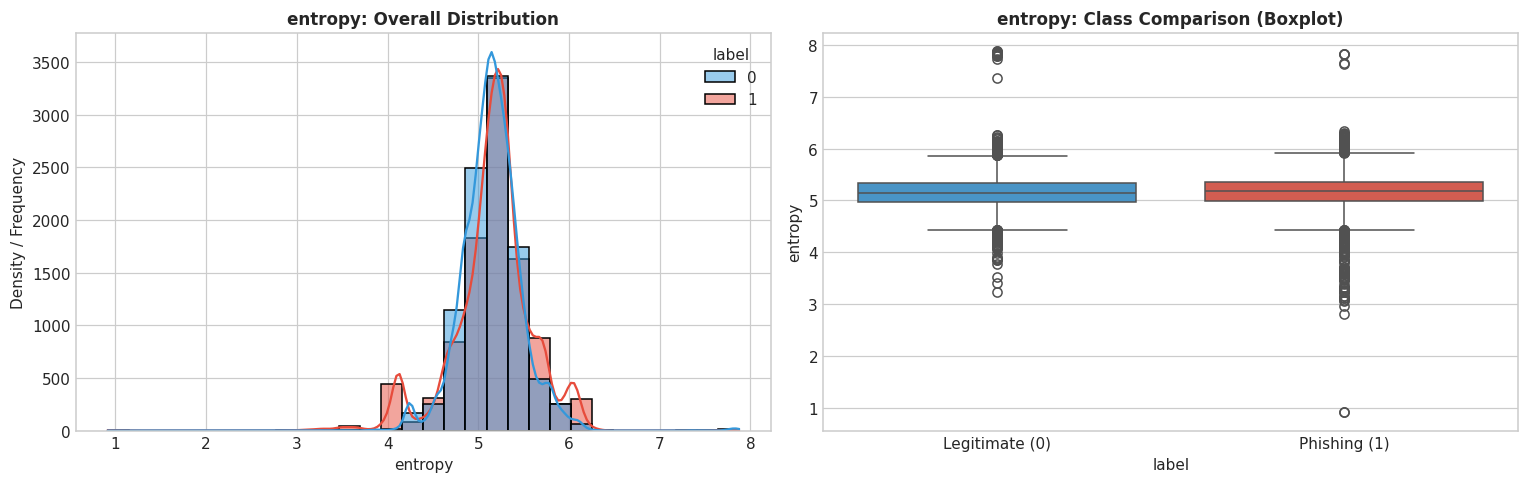

[entropy] Statistics:
  All Samples -> Mean: 5.1548, Median: 5.1687, Skewness: -0.34
  Legitimate  -> Mean: 5.1497, Median: 5.1460, IQR: 0.3589
  Phishing    -> Mean: 5.1599, Median: 5.1874, IQR: 0.3736
  Mann-Whitney U Test: statistic=53,190,657.5, p-value=4.04e-15


In [21]:
# Visualizing distribution and class separation for entropy
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['entropy']
legit_vals = df[df['label'] == 0]['entropy']
phish_vals = df[df['label'] == 1]['entropy']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

# Left Plot: Distribution (KDE & Histogram)
if is_heavy_skew:
    # Use log1p transformation to handle zeros gracefully and prevent KDE singularity
    df_temp = pd.DataFrame({
        'log1p_val': np.log1p(feature_data),
        'label': df['label']
    })
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'entropy: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + entropy)')
else:
    sns.histplot(data=df, x='entropy', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'entropy: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('entropy')

axes[0].set_ylabel('Density / Frequency')

# Right Plot: Boxplot comparison by Class
sns.boxplot(data=df, x='label', y='entropy', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'entropy: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])
axes[1].set_ylabel('entropy')

# Format boxplot y-scale if extreme outliers exist
if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'entropy (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

# Print quantitative breakdown
print(f"[entropy] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Legitimate  -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}, IQR: {legit_vals.quantile(0.75) - legit_vals.quantile(0.25):.4f}")
print(f"  Phishing    -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}, IQR: {phish_vals.quantile(0.75) - phish_vals.quantile(0.25):.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `entropy`**:<br>
- Near-normal bell curve distribution centered at 5.15 (skewness = -0.34).\n- Weak standalone linear correlation with label (Spearman ρ = +0.055, Pearson r = +0.013).\n- Value: Acts as an interaction feature (e.g. ratio with whitespace or script entropy) rather than a strong single discriminator.


#### 3.2.15 `min_link_length`
**Description & Threat Context**:  
Identifies the presence of single-character links (e.g., '#' or '/') vs full explicit URLs. Benign pages frequently use root anchors '#' (median length = 1). Phishing pages often construct redirect paths or absolute link clones (median length = 3).


C:\Users\Panda\AppData\Local\Temp\ipykernel_13424\1670291549.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])


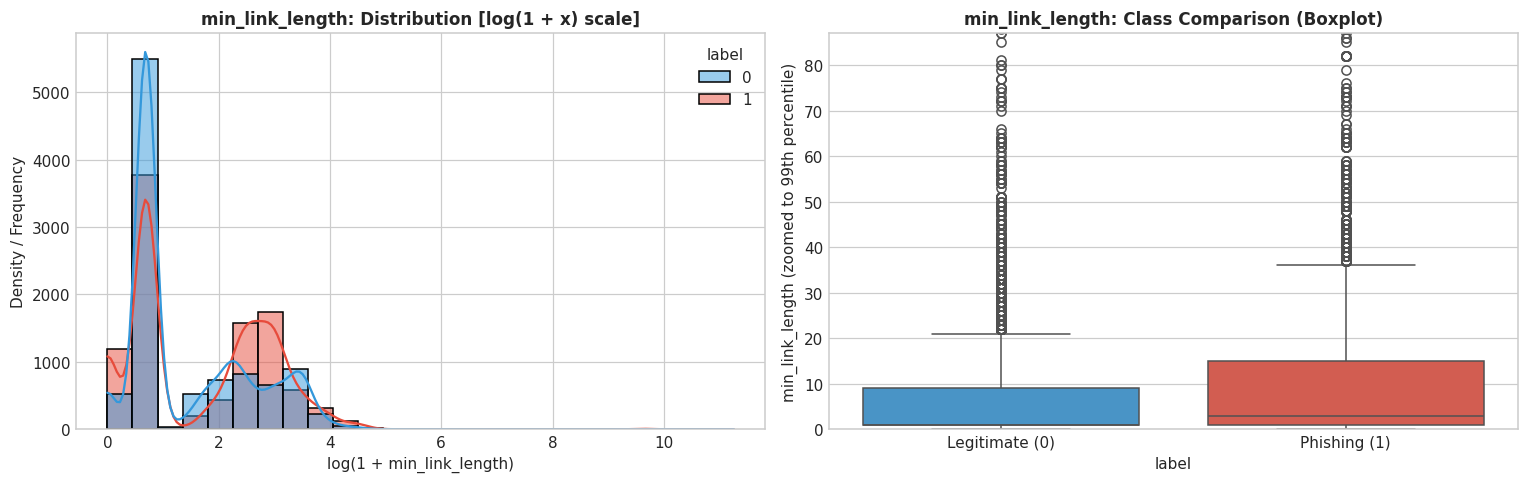

[min_link_length] Statistics:
  All Samples -> Mean: 21.7502, Median: 1.0000, Skewness: 84.03
  Legitimate  -> Mean: 13.1965, Median: 1.0000, IQR: 8.0000
  Phishing    -> Mean: 30.3030, Median: 3.0000, IQR: 14.0000
  Mann-Whitney U Test: statistic=54,255,326.0, p-value=2.72e-28


In [22]:
# Visualizing distribution and class separation for min_link_length
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['min_link_length']
legit_vals = df[df['label'] == 0]['min_link_length']
phish_vals = df[df['label'] == 1]['min_link_length']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

# Left Plot: Distribution (KDE & Histogram)
if is_heavy_skew:
    # Use log1p transformation to handle zeros gracefully and prevent KDE singularity
    df_temp = pd.DataFrame({
        'log1p_val': np.log1p(feature_data),
        'label': df['label']
    })
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'min_link_length: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + min_link_length)')
else:
    sns.histplot(data=df, x='min_link_length', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'min_link_length: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('min_link_length')

axes[0].set_ylabel('Density / Frequency')

# Right Plot: Boxplot comparison by Class
sns.boxplot(data=df, x='label', y='min_link_length', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'min_link_length: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Legitimate (0)', 'Phishing (1)'])
axes[1].set_ylabel('min_link_length')

# Format boxplot y-scale if extreme outliers exist
if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'min_link_length (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

# Print quantitative breakdown
print(f"[min_link_length] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Legitimate  -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}, IQR: {legit_vals.quantile(0.75) - legit_vals.quantile(0.25):.4f}")
print(f"  Phishing    -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}, IQR: {phish_vals.quantile(0.75) - phish_vals.quantile(0.25):.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `min_link_length`**:<br>
- Extreme positive skewness (skewness = 84.03, max = 77,698 chars).\n- Phishing pages exhibit a slightly higher median minimum link length (3 vs 1).\n- Preprocessing: Outlier capping (e.g. at 200 chars) or log transformation is essential.


## 4. Correlation Analysis & Feature Interactions

Understanding inter-feature collinearity is vital to avoid variance inflation in linear models and understand redundant predictors. We compute:
1. **Spearman Rank Correlation Heatmap**: Non-parametric monotonic associations between all 13 features and the target `label`.
2. **Identification of Highly Correlated Pairs** (|r| > 0.60).


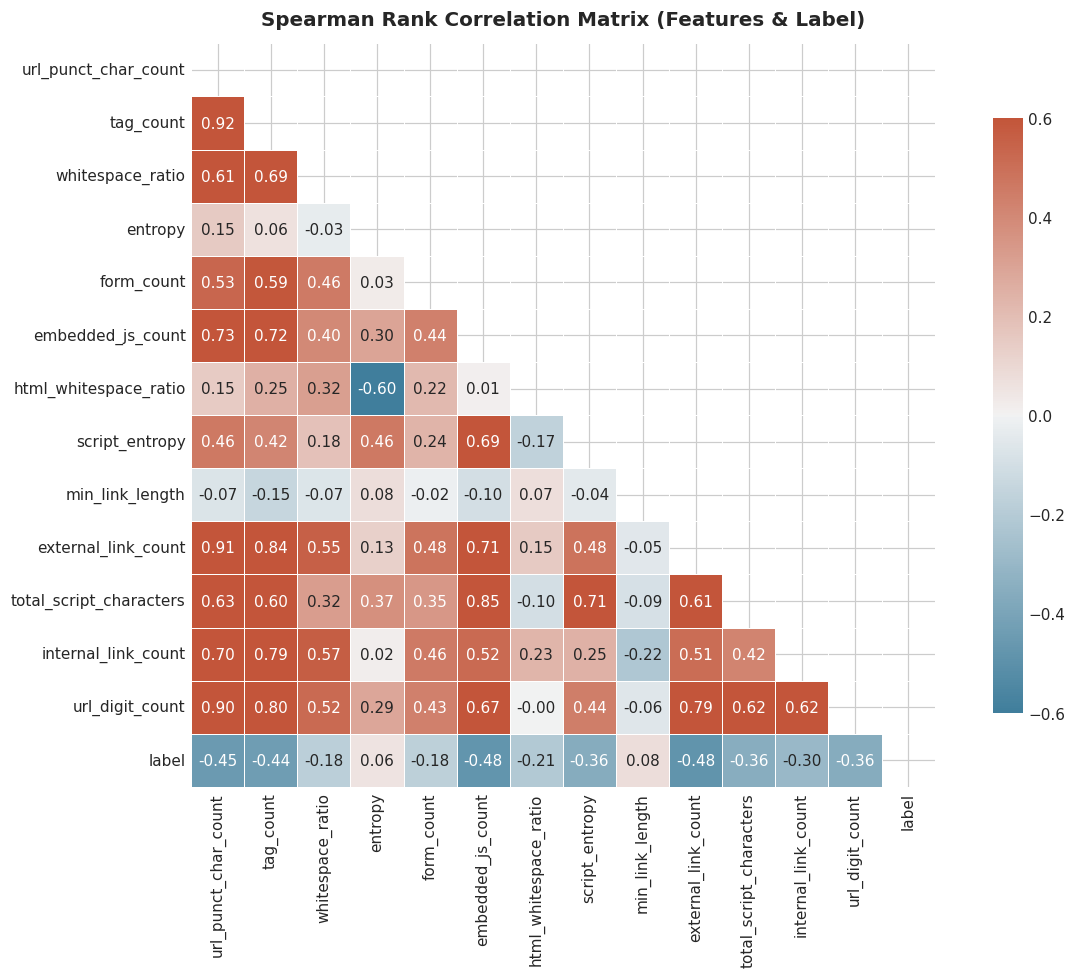

In [23]:
plt.figure(figsize=(12, 9))

# Compute Spearman rank correlation matrix
corr_spearman = df[all_features + ['label']].corr(method='spearman')

# Generate mask for upper triangle
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

cmap = sns.diverging_palette(230, 20, as_cmap=True)
sns.heatmap(corr_spearman, mask=mask, cmap=cmap, vmin=-0.6, vmax=0.6, center=0,
            annot=True, fmt='.2f', square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})

plt.title('Spearman Rank Correlation Matrix (Features & Label)', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


**Findings on Correlations & Multicollinearity**:<br>
- **Top Distinguishers for Legitimate Sites (Negative correlation with `label`)**:
  - `external_link_count` ($\rho = -0.48$)
  - `embedded_js_count` ($\rho = -0.48$)
  - `url_punct_char_count` ($\rho = -0.45$)
  - `tag_count` ($\rho = -0.44$)
  - `total_script_characters` ($\rho = -0.36$)
  - `url_digit_count` ($\rho = -0.36$)
  - `script_entropy` ($\rho = -0.36$)
- **Multicollinearity Checks**:
  - `tag_count` and `internal_link_count` exhibit moderate-high correlation ($r \approx 0.74$), which is natural since DOM size scales with navigation nodes.
  - `entropy` and `html_whitespace_ratio` exhibit negative correlation ($r \approx -0.64$), consistent with information theory (whitespace character repetition lowers entropy).
  - No pairs exceed $|r| > 0.85$, confirming that each of the 13 features captures distinct structural information.


## 5. Summary & Actionable Preprocessing Recommendations

Based on this rigorous exploratory data analysis, we formulate key engineering recommendations for the subsequent preprocessing and model building pipeline:

| Category | Finding | Actionable Engineering Decision |
| :--- | :--- | :--- |
| **Missing Values** | 0 NaN/null values across all records. | No missing value imputation required. |
| **Class Balance** | Exactly 50.0% Legitimate / 50.0% Phishing (19,997 samples). | Standard cross-validation without resampling (SMOTE not needed). |
| **Extreme Skewness** | Count features (`url_punct_char_count`, `min_link_length`, `url_digit_count`, `total_script_characters`, `external_link_count`) have skewness > 10. | Apply `np.log1p()` transformation or `QuantileTransformer` for linear/neural models. |
| **Structural Zeros** | 24.7% zeros in `embedded_js_count`, 18.6% in `external_link_count`. | Create boolean indicator flags (e.g. `has_external_links`, `has_embedded_js`). |
| **Model Selection** | Strong non-linear relationships and heavy outliers. | Gradient Boosted Decision Trees (LightGBM, XGBoost, CatBoost) are ideally suited as primary benchmarks. |
| **Feature Selection Workflow** | High-signal initial subset identified. | Begin training with `use_features = ['embedded_js_count', 'external_link_count', 'tag_count', 'script_entropy', 'url_punct_char_count']`, then incrementally add remaining features. |
